# **MÓDULO 13**
# Projeto - Fundamentos da Descoberta de Dados

Base de produtos de um supermercado do Chile. Aplicamos estatística descritiva (média, mediana, desvio padrão), boxplot, gráfico de barras e mapa interativo.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

## Leitura dos dados

**Atenção:** o arquivo CSV usa **vírgula** como separador (e não `;`, como estava no modelo). Se usássemos `delimiter=';'`, tudo viraria uma coluna só.

In [2]:
df = pd.read_csv("MODULO7_PROJETOFINAL_BASE_SUPERMERCADO.csv")  # separador padrão = vírgula

df.head(10)

,title,Marca,Preco_Normal,Preco_Desconto,Preco_Anterior,Desconto,Categoria
0,"Pack 12 un, Leche extra proteína 1 L",Loncoleche,19788,0,0,0,lacteos
1,"Pack 12 un, Leche chocolate receta original 1 L",Soprole,18228,0,0,0,lacteos
2,"Pack 12 un, Leche semidescremada chocolate 1 L",Soprole,18228,0,0,0,lacteos
3,"Pack 12 un, Leche semidescremada frutilla 1 L",Soprole,18228,0,0,0,lacteos
4,"Pack 12 un, Leche sin lactosa chocolate 1 L",Loncoleche,17988,0,0,0,lacteos
5,"Pack 12 un, Leche sin lactosa frutilla 1 L",Loncoleche,17988,0,0,0,lacteos
6,"Pack 12 un, Leche saborizada light chocolate 1 L",Loncoleche,17988,0,0,0,lacteos
7,"Pack 12 un, Leche saborizada frutilla 1 L",Colun,17388,0,0,0,lacteos
8,"Pack 12 un, Leche saborizada vainilla 1 L",Colun,17388,0,0,0,lacteos
9,"Pack 12 un, Leche saborizada manjar 1 L",Colun,17388,0,0,0,lacteos


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1107 entries, 0 to 1106
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   title           1107 non-null   str  
 1   Marca           1107 non-null   str  
 2   Preco_Normal    1107 non-null   int64
 3   Preco_Desconto  1107 non-null   int64
 4   Preco_Anterior  1107 non-null   int64
 5   Desconto        1107 non-null   int64
 6   Categoria       1107 non-null   str  
dtypes: int64(4), str(3)
memory usage: 60.7 KB


### Um cuidado antes de calcular

Existem produtos com `Preco_Normal = 0`. Pelo enunciado, essas linhas são produtos **em promoção**: o preço está em `Preco_Desconto`, e o `Preco_Normal` ficou vazio (0). Esse **0 não é um preço real**. Se entrar na conta, ele puxa a média e a mediana para baixo e distorce tudo.

Por isso, nas questões 1 a 3 usamos só os produtos com `Preco_Normal > 0`.

In [4]:
print('Produtos com Preco_Normal = 0:', (df['Preco_Normal'] == 0).sum(), 'de', len(df))

# base só com preço normal válido
df_preco = df[df['Preco_Normal'] > 0]
print('Produtos usados nos cálculos de preço:', len(df_preco))

Produtos com Preco_Normal = 0: 294 de 1107
Produtos usados nos cálculos de preço: 813


# 1 - Média e mediana de `Preco_Normal` por categoria

`groupby('Categoria')` separa os produtos em grupos (um por categoria) e calcula a estatística em cada grupo.

In [5]:
# Média por categoria
media = df_preco.groupby('Categoria')['Preco_Normal'].mean().round(2)
media

Categoria
belleza-y-cuidado-personal    2919.66
comidas-preparadas            3954.78
congelados                    3020.67
frutas                        1724.47
instantaneos-y-sopas          1179.27
lacteos                       3028.96
verduras                      1457.14
Name: Preco_Normal, dtype: float64

In [6]:
# Mediana por categoria
mediana = df_preco.groupby('Categoria')['Preco_Normal'].median().round(2)
mediana

Categoria
belleza-y-cuidado-personal    2179.0
comidas-preparadas            3740.0
congelados                    2954.0
frutas                        1195.0
instantaneos-y-sopas           689.0
lacteos                       1719.5
verduras                      1250.0
Name: Preco_Normal, dtype: float64

In [7]:
# Juntando tudo numa tabela e comparando
tabela = pd.DataFrame({'media': media, 'mediana': mediana})
tabela['media - mediana'] = (tabela['media'] - tabela['mediana']).round(2)
tabela['posicao_da_media'] = tabela['media - mediana'].apply(lambda d: 'acima da mediana' if d > 0 else 'abaixo da mediana')
tabela.sort_values('media - mediana', ascending=False)

,media,mediana,media - mediana,posicao_da_media
Categoria,,,,
lacteos,3028.96,1719.5,1309.46,acima da mediana
belleza-y-cuidado-personal,2919.66,2179.0,740.66,acima da mediana
frutas,1724.47,1195.0,529.47,acima da mediana
instantaneos-y-sopas,1179.27,689.0,490.27,acima da mediana
comidas-preparadas,3954.78,3740.0,214.78,acima da mediana
verduras,1457.14,1250.0,207.14,acima da mediana
congelados,3020.67,2954.0,66.67,acima da mediana


**Categorias com média acima ou abaixo da mediana:**

- **Média ACIMA da mediana: todas as 7 categorias.** As maiores diferenças estão em `lacteos` (~1.310 pesos), `belleza-y-cuidado-personal` (~741), `frutas` (~530) e `instantaneos-y-sopas` (~490).
- **Média ABAIXO da mediana:** nenhuma.
- Em `congelados` (~67) a média e a mediana são quase iguais, ou seja, a distribuição ali é mais simétrica.

**Por que a média fica acima?** Poucos produtos muito caros (como packs de 12 caixas de leite e fraldas) puxam a média para cima, mas quase não mexem na mediana. A mediana é o valor do "meio" e resiste a extremos. Os preços estão em **pesos chilenos**.

# 2 - Desvio padrão por categoria

O desvio padrão mede o quanto os preços se **espalham** em volta da média. Quanto maior, mais heterogêneos são os preços da categoria.

In [8]:
desvio = df_preco.groupby('Categoria')['Preco_Normal'].std().round(2)
tabela['desvio_padrao'] = desvio
tabela.sort_values('desvio_padrao', ascending=False)[['media', 'mediana', 'desvio_padrao']]

,media,mediana,desvio_padrao
Categoria,,,
lacteos,3028.96,1719.5,4198.57
belleza-y-cuidado-personal,2919.66,2179.0,2162.65
congelados,3020.67,2954.0,1904.48
frutas,1724.47,1195.0,1639.15
comidas-preparadas,3954.78,3740.0,1322.33
instantaneos-y-sopas,1179.27,689.0,1276.22
verduras,1457.14,1250.0,972.23


In [9]:
categoria_maior_desvio = desvio.idxmax()
print('Categoria com maior desvio padrão:', categoria_maior_desvio, '->', desvio.max())

Categoria com maior desvio padrão: lacteos -> 4198.57


**Comportamento nas categorias com maior desvio:**

`lacteos` tem o maior desvio (~4.199), seguida de `belleza-y-cuidado-personal` (~2.163) e `congelados` (~1.905). Nelas, a **média é bem maior que a mediana**. Em `lacteos` a média é ~3.029 e a mediana ~1.720.

Isso mostra uma distribuição **assimétrica à direita**: a maioria dos produtos é barata, mas existem poucos muito caros (packs de 12 litros de leite, leite em pó em tarro grande) que esticam a "cauda" e inflam a média e o desvio. Nesses casos a **mediana representa melhor o produto típico**.

# 3 - Boxplot de `Preco_Normal` da categoria com maior desvio (`lacteos`)

O boxplot mostra: a caixa (do 1º ao 3º quartil, onde estão 50% dos produtos), a linha dentro dela (mediana) e os pontos isolados (possíveis **outliers**).

/tmp/ipykernel_151/1053235849.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df_lacteos['Preco_Normal'], vert=True, patch_artist=True,


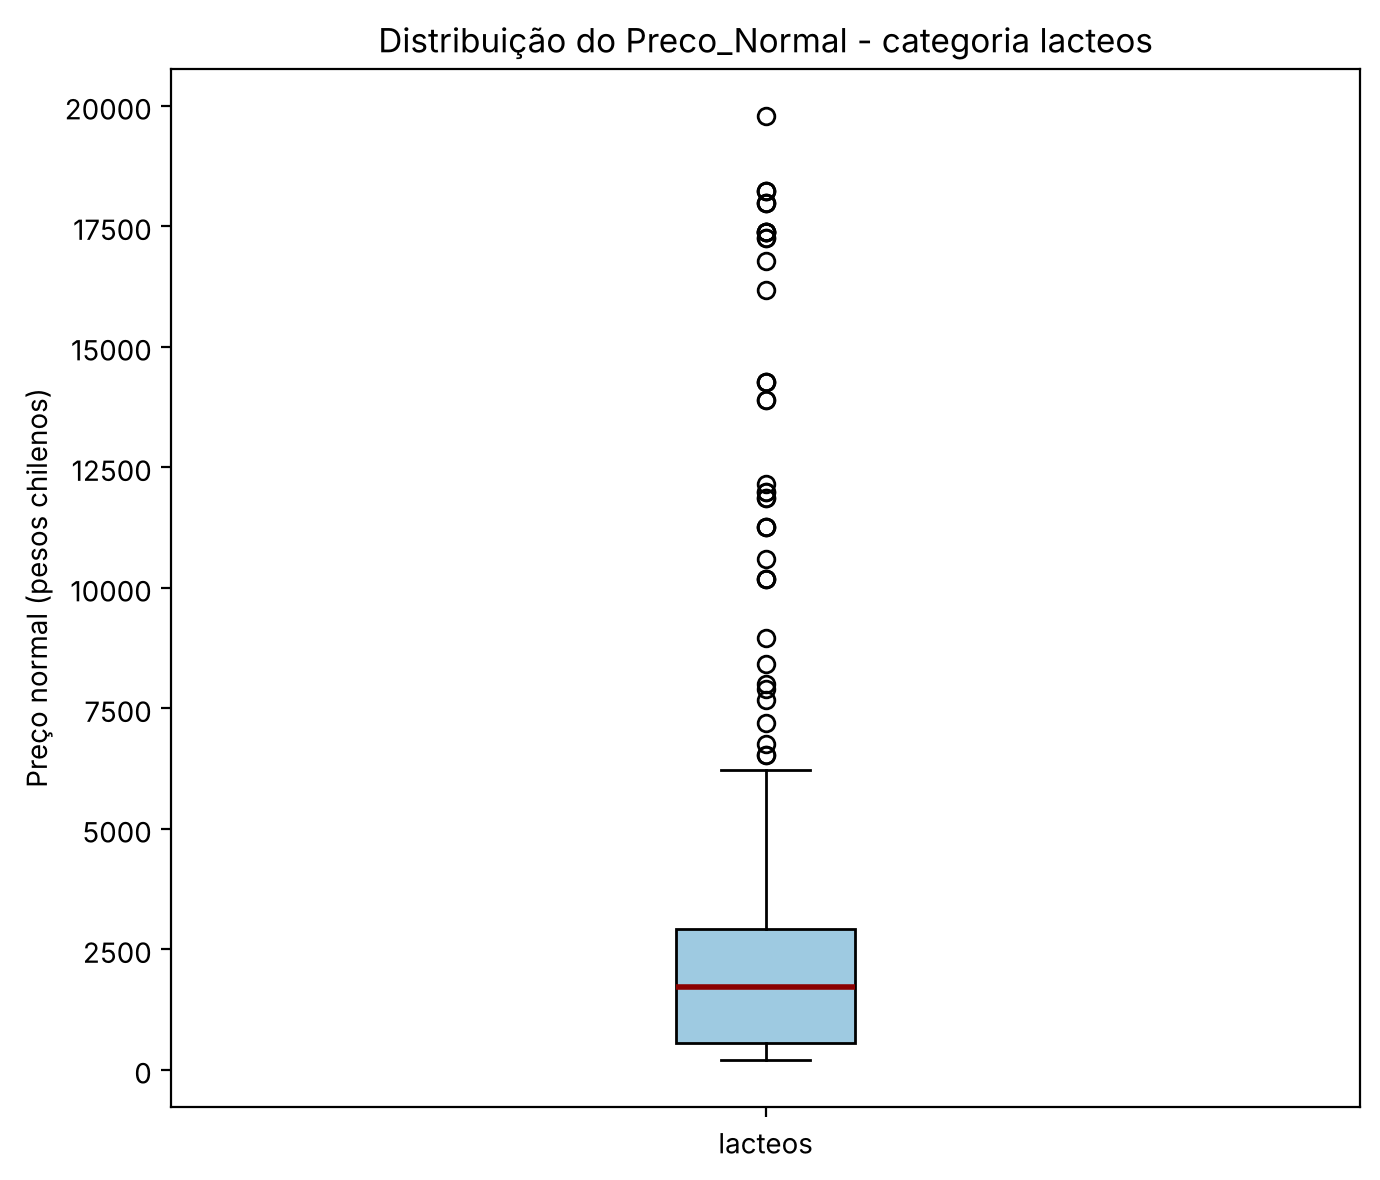

In [10]:
df_lacteos = df_preco.loc[df_preco['Categoria'] == categoria_maior_desvio]

fig, ax = plt.subplots(figsize=(7, 6))
ax.boxplot(df_lacteos['Preco_Normal'], vert=True, patch_artist=True,
           boxprops=dict(facecolor='#9ecae1'), medianprops=dict(color='darkred', linewidth=2))
ax.set_title('Distribuição do Preco_Normal - categoria lacteos')
ax.set_ylabel('Preço normal (pesos chilenos)')
ax.set_xticklabels(['lacteos'])
plt.tight_layout()
plt.savefig('graficos/1_boxplot_lacteos.png', dpi=150)
plt.show()

## Identificando os outliers

O boxplot marca como outlier quem passa de **Q3 + 1,5 × IQR** (ou fica abaixo de **Q1 − 1,5 × IQR**), onde IQR = Q3 − Q1. Vamos calcular isso na mão para saber exatamente quais são.

In [11]:
q1 = df_lacteos['Preco_Normal'].quantile(0.25)
q3 = df_lacteos['Preco_Normal'].quantile(0.75)
iqr = q3 - q1
limite_inf = q1 - 1.5 * iqr
limite_sup = q3 + 1.5 * iqr
print(f'Q1={q1:.0f}  Q3={q3:.0f}  IQR={iqr:.0f}')
print(f'Limites: inferior={limite_inf:.0f}  superior={limite_sup:.0f}')

outliers = df_lacteos[(df_lacteos['Preco_Normal'] < limite_inf) | (df_lacteos['Preco_Normal'] > limite_sup)]
print('Quantidade de outliers:', len(outliers), 'de', len(df_lacteos), 'produtos')
outliers[['title', 'Marca', 'Preco_Normal']].sort_values('Preco_Normal', ascending=False)

Q1=559  Q3=2929  IQR=2370
Limites: inferior=-2996  superior=6484
Quantidade de outliers: 42 de 352 produtos


,title,Marca,Preco_Normal
0,"Pack 12 un, Leche extra proteína 1 L",Loncoleche,19788
1,"Pack 12 un, Leche chocolate receta original 1 L",Soprole,18228
2,"Pack 12 un, Leche semidescremada chocolate 1 L",Soprole,18228
3,"Pack 12 un, Leche semidescremada frutilla 1 L",Soprole,18228
4,"Pack 12 un, Leche sin lactosa chocolate 1 L",Loncoleche,17988
5,"Pack 12 un, Leche sin lactosa frutilla 1 L",Loncoleche,17988
6,"Pack 12 un, Leche saborizada light chocolate 1 L",Loncoleche,17988
7,"Pack 12 un, Leche saborizada frutilla 1 L",Colun,17388
8,"Pack 12 un, Leche saborizada vainilla 1 L",Colun,17388
9,"Pack 12 un, Leche saborizada manjar 1 L",Colun,17388


In [12]:
# Resumo por tipo de produto: quantos outliers são 'Pack 12 un'?
print('Outliers que são Pack 12 un:', outliers['title'].str.contains('Pack 12').sum())
print('Maior preço:', outliers['Preco_Normal'].max())

Outliers que são Pack 12 un: 30
Maior preço: 19788


**Interpretação do boxplot:**

- A **caixa é baixa**: 50% dos lácteos custam entre ~559 e ~2.929 pesos, e a mediana (~1.720) fica na parte de baixo da caixa.
- O **bigode superior termina em ~6.484** (limite do IQR) e há muitos pontos acima dele: a distribuição é **assimétrica à direita**.
- **Sim, há muitos outliers: 42 de 352 produtos (cerca de 12%)**, todos no lado de cima. Não há outliers abaixo, porque os preços já são baixos.
- Os outliers vão de ~6.534 a **19.788 pesos**. **30 deles são "Pack 12 un" de leite**; os demais são leites em pó (Nido, Colun, Svelty...) e alguns packs de 6 unidades. Não são erros de digitação: são embalagens grandes, naturalmente mais caras que um iogurte de ~250 pesos.

# 4 - Gráfico de barras: média de desconto por categoria

A coluna `Desconto` vale 0 quando não houve desconto. Aqui consideramos **todos os produtos** da categoria, então a média representa o desconto médio por produto do catálogo (os zeros entram na conta).

In [13]:
media_desconto = df.groupby('Categoria')['Desconto'].mean().sort_values(ascending=False).round(2)
media_desconto

Categoria
congelados                    154.03
belleza-y-cuidado-personal    123.08
comidas-preparadas             43.48
lacteos                        17.41
frutas                          0.00
instantaneos-y-sopas            0.00
verduras                        0.00
Name: Desconto, dtype: float64

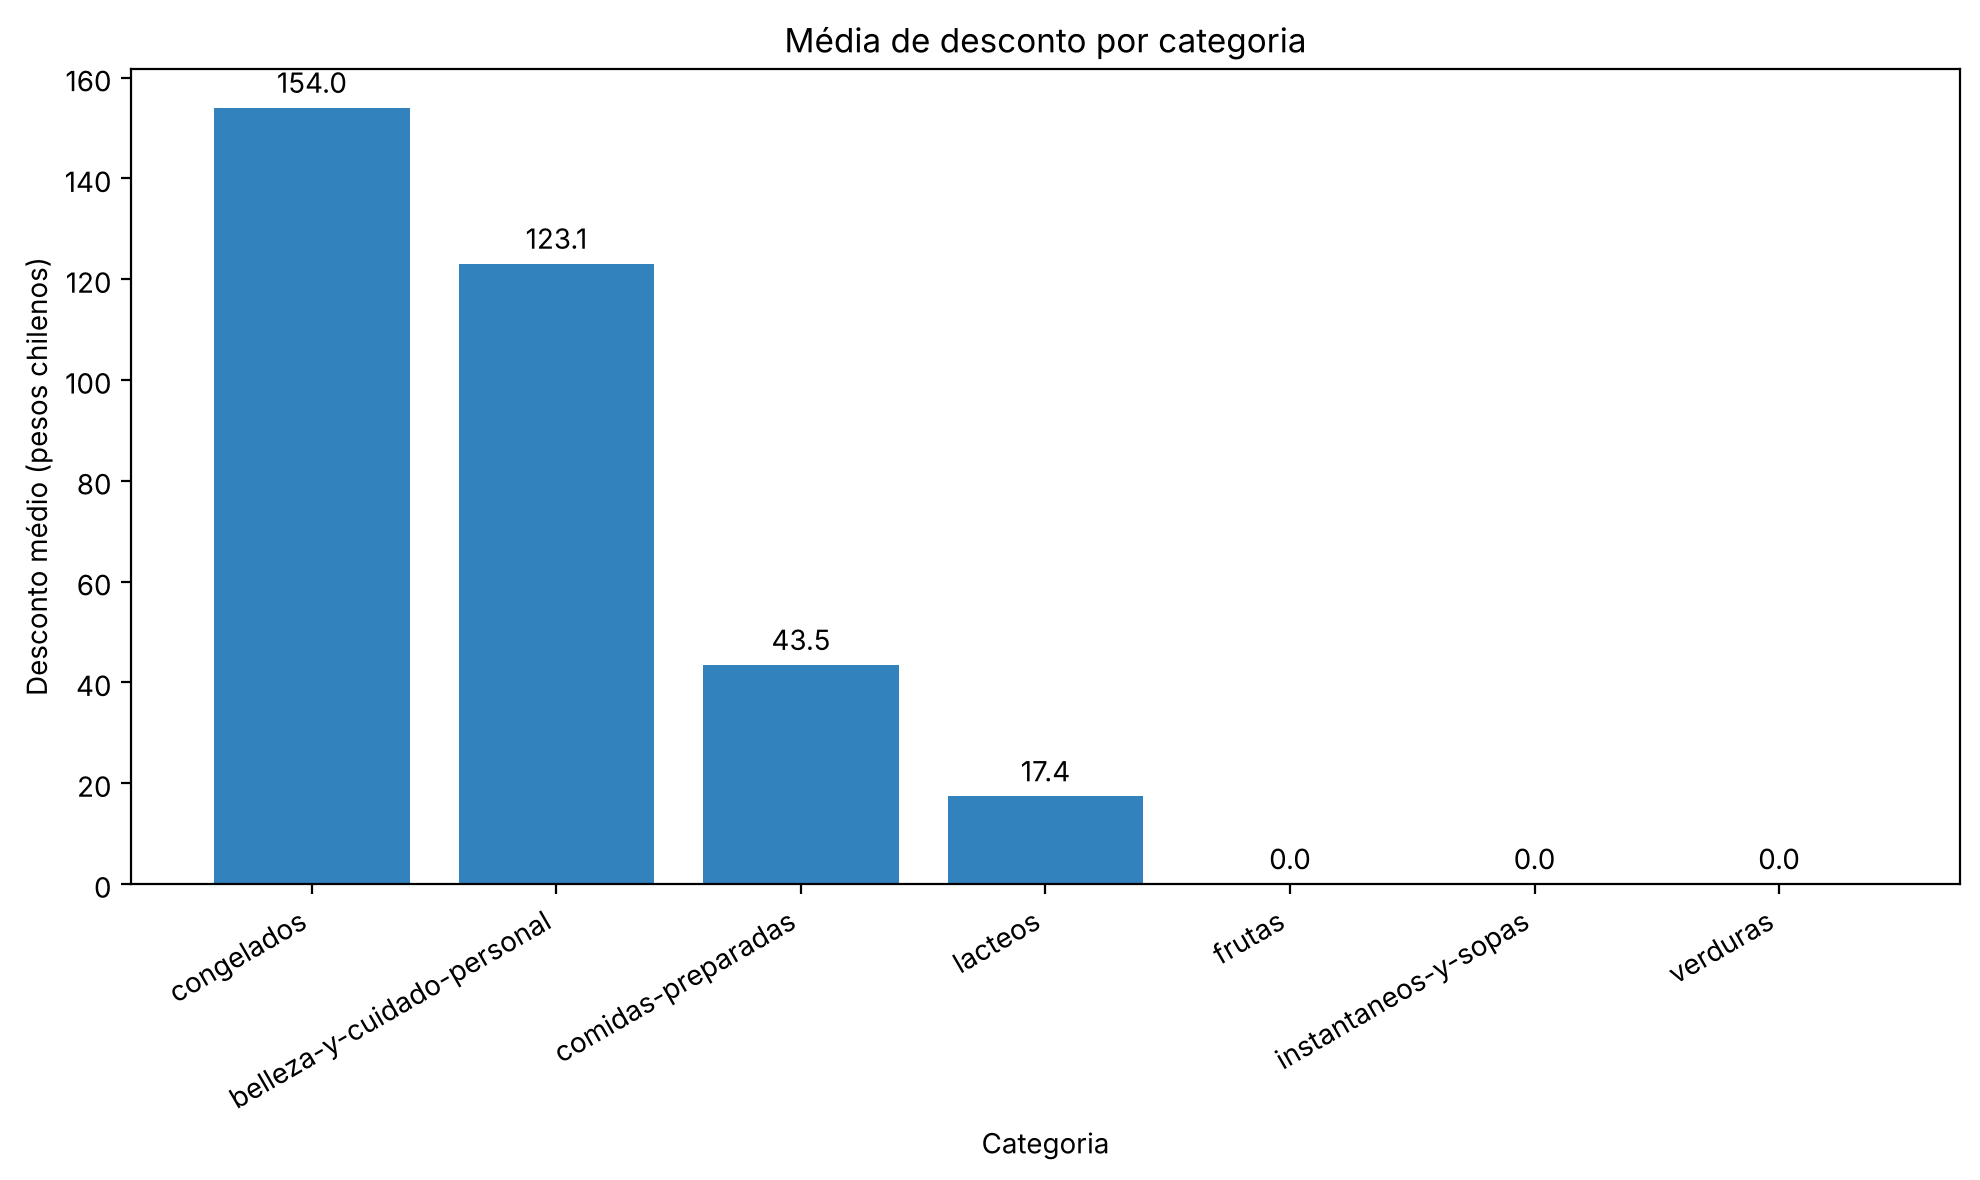

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))
barras = ax.bar(media_desconto.index, media_desconto.values, color='#3182bd')
ax.bar_label(barras, fmt='%.1f', padding=3)
ax.set_title('Média de desconto por categoria')
ax.set_xlabel('Categoria')
ax.set_ylabel('Desconto médio (pesos chilenos)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('graficos/2_barras_media_desconto.png', dpi=150)
plt.show()

**Leitura (valores em pesos chilenos):** `congelados` (~154) e `belleza-y-cuidado-personal` (~123) têm os maiores descontos médios. `lacteos` e `comidas-preparadas` têm descontos pequenos, e `frutas`, `verduras` e `instantaneos-y-sopas` têm média **zero** (nenhum produto dessas categorias tem desconto registrado).

# 5 - Mapa interativo (treemap) por categoria e marca com a média de desconto

No treemap, cada retângulo grande é uma **categoria** e dentro dele ficam as **marcas**. A **cor** indica a média de desconto e o **tamanho** indica quantos produtos a marca tem. Passe o mouse para ver os valores e clique para entrar em uma categoria.

In [15]:
agrupado = (df.groupby(['Categoria', 'Marca'])
            .agg(media_desconto=('Desconto', 'mean'), qtd_produtos=('title', 'count'))
            .reset_index())
agrupado['media_desconto'] = agrupado['media_desconto'].round(2)
agrupado.head()

,Categoria,Marca,media_desconto,qtd_produtos
0,belleza-y-cuidado-personal,Always,123.75,4
1,belleza-y-cuidado-personal,Aquafresh,444.67,3
2,belleza-y-cuidado-personal,Axe,590.00,1
3,belleza-y-cuidado-personal,Babyland,0.00,1
4,belleza-y-cuidado-personal,Ballerina,34.08,12


In [16]:
fig = px.treemap(
    agrupado,
    path=[px.Constant('Supermercado'), 'Categoria', 'Marca'],
    values='qtd_produtos',
    color='media_desconto',
    color_continuous_scale='YlOrRd',
    hover_data={'media_desconto': ':.1f', 'qtd_produtos': True},
    title='Média de desconto por categoria e marca (tamanho = nº de produtos)'
)
fig.update_layout(margin=dict(t=60, l=10, r=10, b=10), width=1100, height=700)
fig.write_html('graficos/3_mapa_interativo.html')
try:
    fig.write_image('graficos/3_mapa_interativo.png', scale=2)
except Exception as e:
    print('PNG não gerado:', e)
fig.show()

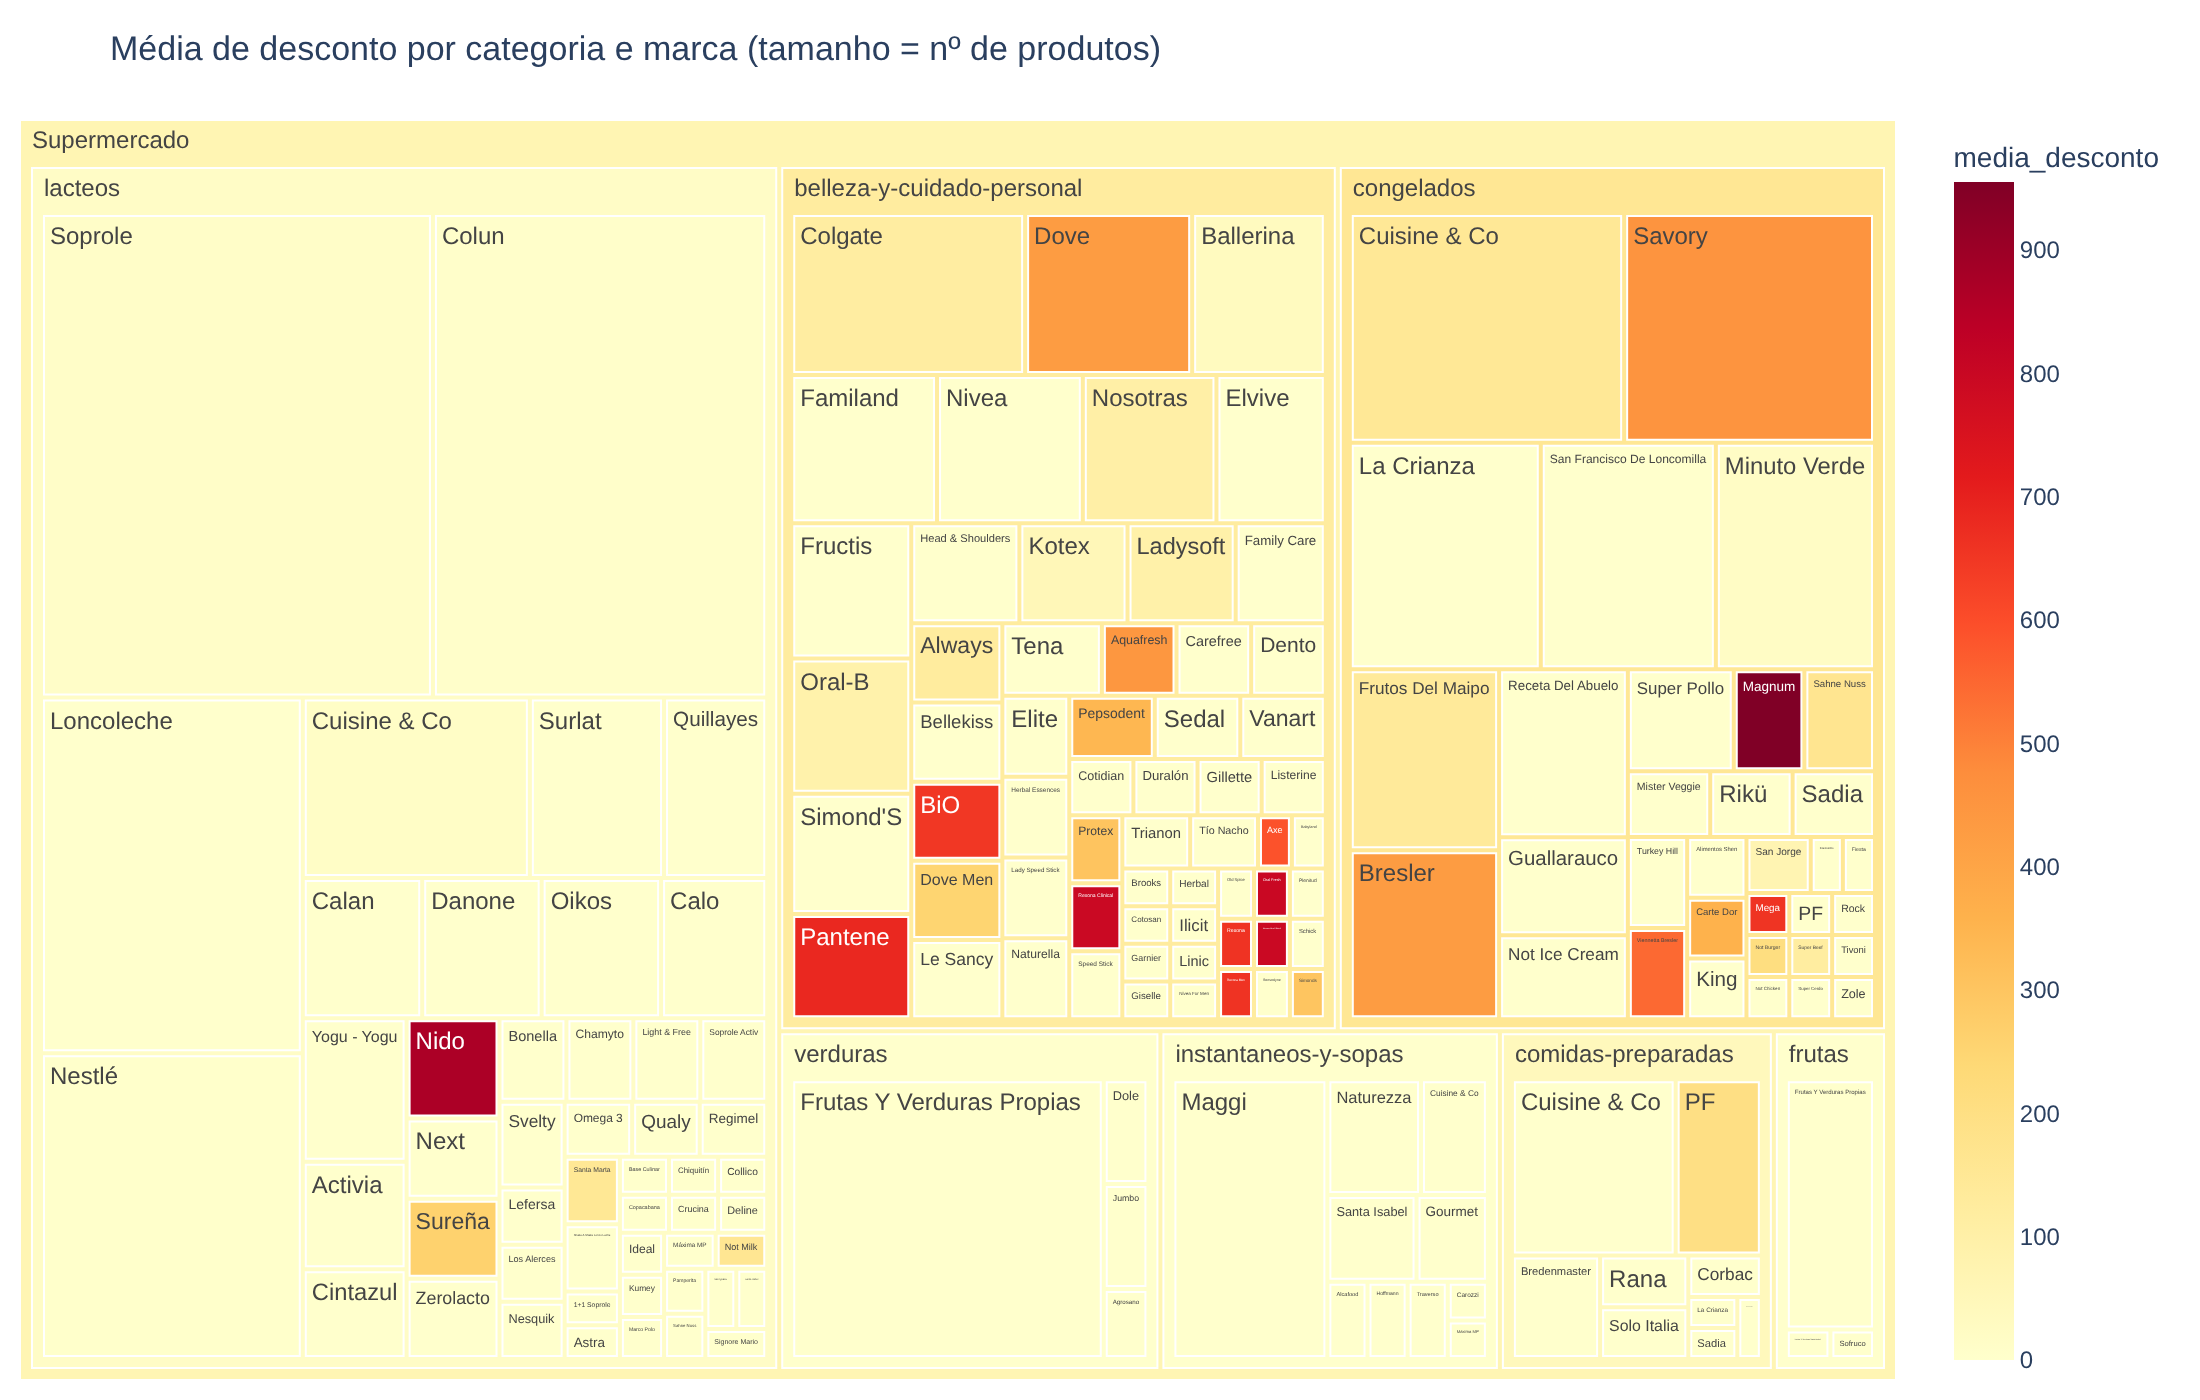

In [17]:
# Versão estática do mapa (aparece também no GitHub, que não executa gráficos interativos)
from IPython.display import Image, display
display(Image('graficos/3_mapa_interativo.png'))

**Leitura:** as marcas mais escuras (maior média de desconto) concentram-se em `congelados` e `belleza-y-cuidado-personal` (por exemplo Bresler, Savory, Dove, Pantene). Em `lacteos` quase tudo é claro (desconto baixo).

---
## Resumo das conclusões
1. Em todas as categorias com diferença relevante, a **média fica acima da mediana**, sinal de poucos produtos muito caros.
2. `lacteos` tem o **maior desvio padrão** e o boxplot mostra **muitos outliers** no lado superior (packs e leites em pó).
3. Os maiores descontos médios estão em `congelados` e `belleza-y-cuidado-personal`.